the detector

In [1]:
pip install ipywidgets

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from transformers import Owlv2Processor, Owlv2ForObjectDetection
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# --- 1. SETUP MODEL ---
device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "google/owlv2-base-patch16-ensemble"
processor = Owlv2Processor.from_pretrained(model_id)
model = Owlv2ForObjectDetection.from_pretrained(model_id).to(device)
model.eval()

# --- 2. LOAD YOUR REFERENCE CROPS (MULTI-ANGLE) ---
# Pick 2-3 clean crops of Lenny from your "base Lenny" photos
REFERENCE_CROPS = [
    Image.open("images/lenny1.jpg").convert("RGB"),
    Image.open("images/lenny2.jpg").convert("RGB"),
    Image.open("images/lenny3.jpg").convert("RGB"),
    Image.open("images/lenny4.jpg").convert("RGB"),
    Image.open("images/lenny5.jpg").convert("RGB"),
    Image.open("images/lenny6.jpg").convert("RGB"),
    Image.open("images/lenny7.jpg").convert("RGB"),
    Image.open("images/lenny8.jpg").convert("RGB"),
    Image.open("images/lenny9.jpg").convert("RGB")
]

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

open training images

Total Sample Images  : {len(image_files)}
20261010_192839.jpg -> Size: (4000, 3000) (W x H)
20261010_192844.jpg -> Size: (4000, 3000) (W x H)
20261010_192848.jpg -> Size: (4000, 3000) (W x H)
20261010_192852.jpg -> Size: (4000, 3000) (W x H)
20261010_192856.jpg -> Size: (4000, 3000) (W x H)


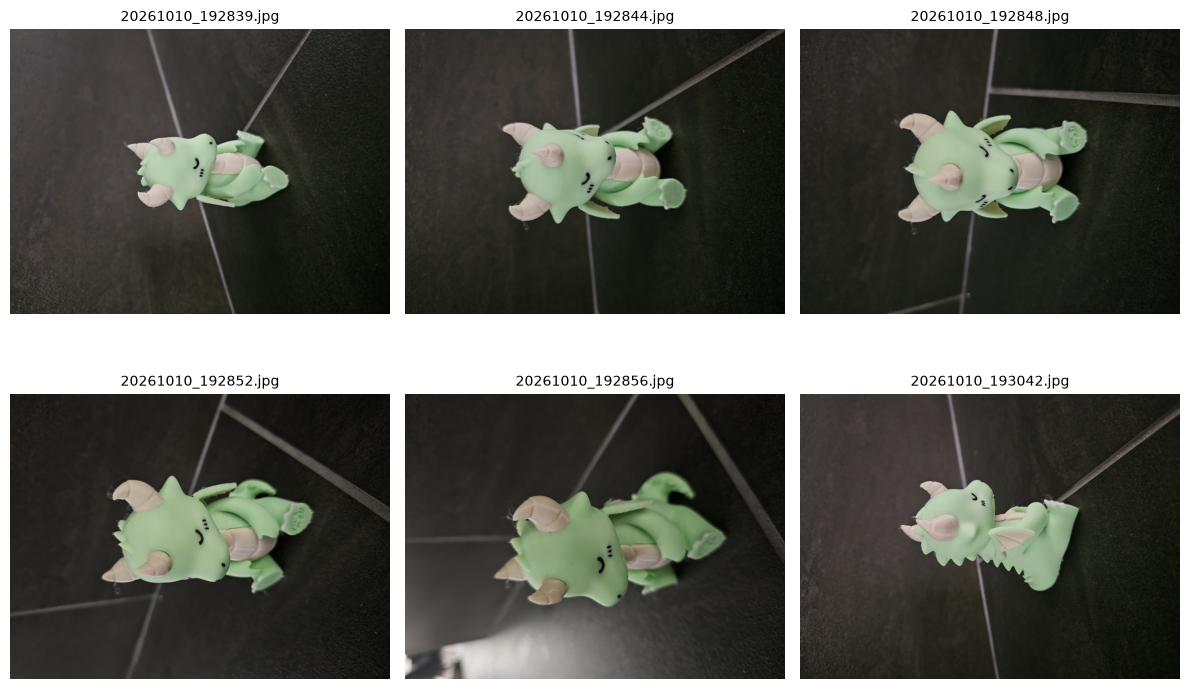

In [3]:
image_dir = Path("images")
image_files = sorted(list(image_dir.glob("*.jpg")) + list(image_dir.glob("*.png")) + list(image_dir.glob("*.jpeg")))

print("Total Sample Images  : {len(image_files)}")

# 2. Check dimensions of first few images (EDA resolution check)
for p in image_files[:5]:
    with Image.open(p) as img:
        print(f"{p.name} -> Size: {img.size} (W x H)")

# 3. Visual EDA: Plot a 2x3 grid of sample photos
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    if i < len(image_files):
        img = Image.open(image_files[i])
        ax.imshow(img)
        ax.set_title(image_files[i].name, fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
def get_lenny_coords(
    image_bytes: bytes,
    size_coords: tuple,                     # (xmin, ymin, xmax, ymax)
    reference_crops: list = REFERENCE_CROPS,
    threshold: float = 0.55                 # Image-guided threshold (0.50 - 0.65)
):
    """
    Scans the room photo against multiple reference angles of Lenny.
    Filters candidate boxes by target dimensions.
    Returns: (center_x, center_y) or (None, None).
    """
    # 1. Target scale from user's box
    u_xmin, u_ymin, u_xmax, u_ymax = size_coords
    target_area = max(abs(u_xmax - u_xmin) * abs(u_ymax - u_ymin), 1)

    # 2. Decode the search image
    search_image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
    width, height = search_image.size
    target_sizes = torch.tensor([[height, width]]).to(device)

    best_candidate_box = None
    best_overall_score = -float("inf")

    # 3. Test each reference angle (Front, Side, Back)
    for ref_crop in reference_crops:
        inputs = processor(
            images=search_image,
            query_images=ref_crop,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model.image_guided_detection(**inputs)

        results = processor.post_process_image_guided_detection(
            outputs=outputs,
            threshold=threshold,
            target_sizes=target_sizes
        )[0]

        boxes = results["boxes"]
        scores = results["scores"]

        if len(boxes) == 0:
            continue

        # 4. Score candidates against expected size
        for box, score in zip(boxes, scores):
            b = box.tolist()  # [xmin, ymin, xmax, ymax]
            box_area = max(abs(b[2] - b[0]) * abs(b[3] - b[1]), 1)

            scale_ratio = box_area / target_area
            if scale_ratio > 1.0:
                scale_ratio = 1.0 / scale_ratio

            # Combined confidence and size similarity
            rank_score = float(score) * (scale_ratio ** 0.5)

            if rank_score > best_overall_score:
                best_overall_score = rank_score
                best_candidate_box = b

    # If no angle found Lenny above threshold
    if best_candidate_box is None:
        return None, None

    # 5. Return strictly the center coordinates
    center_x = round((best_candidate_box[0] + best_candidate_box[2]) / 2)
    center_y = round((best_candidate_box[1] + best_candidate_box[3]) / 2)

    return center_x, center_y

test function with test data

In [5]:
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import io
import torch

# 1. Define the filenames of your 9 base reference images so the tester skips them
BASE_IMAGE_FILENAMES = [
    "lenny1.jpg", "lenny3.jpg", "lenny4.jpg",
    "lenny2.jpg", "lenny5.jpg", "lenny6.jpg",
    "lenny8.jpg", "lenny9.jpg", "lenny7.jpg"
]

# Load the 9 reference crops into memory
REFERENCE_CROPS = [
    Image.open(f"images/{fname}").convert("RGB")
    for fname in BASE_IMAGE_FILENAMES
]


def test_remaining_images(
    image_dir: str = "images",
    reference_crops: list = REFERENCE_CROPS,
    base_filenames: list = BASE_IMAGE_FILENAMES,
    default_box_size: tuple = (0, 0, 100, 100),  # Expected [xmin, ymin, xmax, ymax] scale
    threshold: float = 0.55                      # Confidence threshold (0.50 - 0.65)
):
    """
    Tests all images in the folder EXCEPT the base reference images.
    Displays each photo with a box and center marker where Lenny is detected.
    """
    img_dir = Path(image_dir)
    all_files = sorted(
        list(img_dir.glob("*.jpg")) + 
        list(img_dir.glob("*.png")) + 
        list(img_dir.glob("*.jpeg"))
    )

    # Filter out your 9 base images
    test_files = [p for p in all_files if p.name not in base_filenames]
    print(f"Testing {len(test_files)} game photos against all {len(reference_crops)} base angles...\n")

    # Target scale from default box size
    target_area = max(abs(default_box_size[2] - default_box_size[0]) * abs(default_box_size[3] - default_box_size[1]), 1)

    for img_path in test_files:
        with open(img_path, "rb") as f:
            search_image = Image.open(f).convert("RGB")
        
        width, height = search_image.size
        target_sizes = torch.tensor([[height, width]]).to(device)

        best_box = None
        best_overall_score = -float("inf")

        # Check the photo against each of the 9 base reference angles
        for ref_crop in reference_crops:
            inputs = processor(
                images=search_image,
                query_images=ref_crop,
                return_tensors="pt"
            ).to(device)

            with torch.no_grad():
                outputs = model.image_guided_detection(**inputs)

            results = processor.post_process_image_guided_detection(
                outputs=outputs,
                threshold=threshold,
                target_sizes=target_sizes
            )[0]

            boxes = results["boxes"]
            scores = results["scores"]

            if len(boxes) == 0:
                continue

            for box, score in zip(boxes, scores):
                b = box.tolist()  # [xmin, ymin, xmax, ymax]
                box_area = max(abs(b[2] - b[0]) * abs(b[3] - b[1]), 1)

                scale_ratio = box_area / target_area
                if scale_ratio > 1.0:
                    scale_ratio = 1.0 / scale_ratio

                rank_score = float(score) * (scale_ratio ** 0.5)

                if rank_score > best_overall_score:
                    best_overall_score = rank_score
                    best_box = b

        # --- Plot and Draw Output ---
        display_img = search_image.copy()
        draw = ImageDraw.Draw(display_img)

        plt.figure(figsize=(7, 5))

        if best_box is not None:
            xmin, ymin, xmax, ymax = [round(v) for v in best_box]
            cx = round((xmin + xmax) / 2)
            cy = round((ymin + ymax) / 2)

            # Draw green bounding box around Lenny
            draw.rectangle([xmin, ymin, xmax, ymax], outline="#00FF00", width=4)
            
            # Draw yellow center point dot
            r = 6
            draw.ellipse((cx - r, cy - r, cx + r, cy + r), fill="yellow", outline="black", width=2)

            plt.title(f"{img_path.name} | FOUND at ({cx}, {cy}) | Score: {best_overall_score:.2f}", color="green", fontsize=11)
        else:
            plt.title(f"{img_path.name} | NOT DETECTED (No Lenny)", color="red", fontsize=11)

        plt.imshow(display_img)
        plt.axis("off")
        plt.show()